# Лабораторная 3 — простой GAN на MNIST


**Студент:** Цурцурика Илья <br>
**Группа:** IASD2501 <br>
**Дисциплина:** Intelligenta Artificiala Generativa

Архитектура Гудфеллоу (2014): z → Генератор → изображение → Дискриминатор → real/fake.


## Шаг 0 — Подготовка

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Загружаем MNIST (метки нам не нужны)
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Нормализация в [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Сплющиваем каждую картинку 28x28 в вектор длиной 784
x_train = x_train.reshape(-1, 784)

latent_dim = 100
BATCH_SIZE = 128

# Батчи по 128 (drop_remainder, чтобы размер батча всегда был ровно 128)
dataset = (tf.data.Dataset.from_tensor_slices(x_train)
           .shuffle(60000)
           .batch(BATCH_SIZE, drop_remainder=True))

print(x_train.shape, x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 784) -1.0 1.0


## Шаг 1 — Генератор

In [2]:
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(latent_dim,)),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dense(784, activation="tanh"),  # выход в [-1, 1]
], name="generator")

generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,632 (2.13 MB)

 Trainable params: 559,632 (2.13 MB)

 Non-trainable params: 0 (0.00 B)

## Шаг 2 — Дискриминатор

In [3]:
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid"),  # вероятность "настоящее"
], name="discriminator")

discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

## Шаг 3 — Обучение

In [4]:
bce = tf.keras.losses.BinaryCrossentropy()
g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(real):
    # ---------- 1) Обучаем дискриминатор ----------
    z = tf.random.normal((BATCH_SIZE, latent_dim))
    fake = generator(z)
    with tf.GradientTape() as tape:
        d_loss = (bce(tf.ones((BATCH_SIZE, 1)), discriminator(real)) +
                  bce(tf.zeros((BATCH_SIZE, 1)), discriminator(fake)))
    grads = tape.gradient(d_loss, discriminator.trainable_variables)
    d_opt.apply_gradients(zip(grads, discriminator.trainable_variables))

    # ---------- 2) Обучаем генератор ----------
    z = tf.random.normal((BATCH_SIZE, latent_dim))
    with tf.GradientTape() as tape:
        # генератор хочет, чтобы подделки считались настоящими (метка 1)
        g_loss = bce(tf.ones((BATCH_SIZE, 1)), discriminator(generator(z)))
    grads = tape.gradient(g_loss, generator.trainable_variables)
    g_opt.apply_gradients(zip(grads, generator.trainable_variables))

    return d_loss, g_loss


def show_grid(images, rows, cols, title=None):
    """images: массив (N, 784) в диапазоне [-1, 1]"""
    images = (images + 1) / 2  # обратно в [0, 1]
    plt.figure(figsize=(cols * 1.2, rows * 1.2))
    for i in range(rows * cols):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
    if title:
        plt.suptitle(title)
    plt.show()

Эпоха 1/30  d_loss=1.021  g_loss=1.350


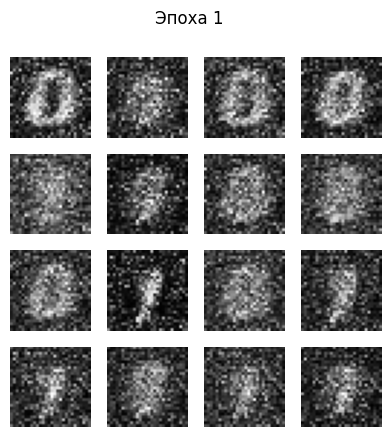

Эпоха 2/30  d_loss=0.873  g_loss=1.503
Эпоха 3/30  d_loss=0.810  g_loss=1.652
Эпоха 4/30  d_loss=0.820  g_loss=1.607
Эпоха 5/30  d_loss=0.786  g_loss=1.749


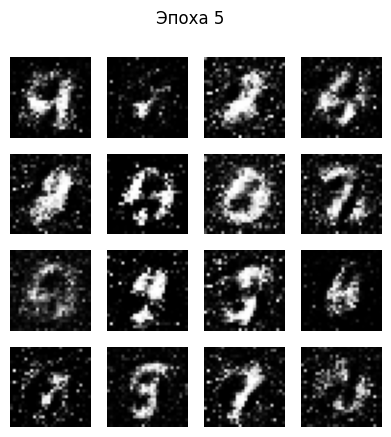

Эпоха 6/30  d_loss=0.846  g_loss=1.579
Эпоха 7/30  d_loss=0.793  g_loss=1.643
Эпоха 8/30  d_loss=0.764  g_loss=1.711
Эпоха 9/30  d_loss=0.770  g_loss=1.714
Эпоха 10/30  d_loss=0.797  g_loss=1.675


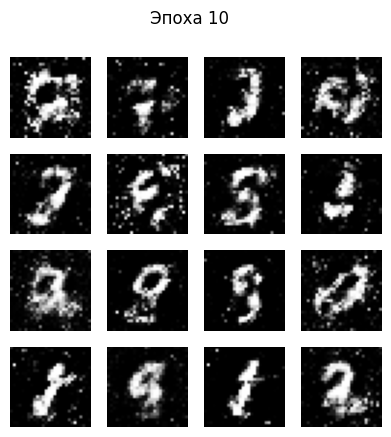

Эпоха 11/30  d_loss=0.822  g_loss=1.603
Эпоха 12/30  d_loss=0.887  g_loss=1.469
Эпоха 13/30  d_loss=0.919  g_loss=1.437
Эпоха 14/30  d_loss=0.937  g_loss=1.381
Эпоха 15/30  d_loss=0.955  g_loss=1.341


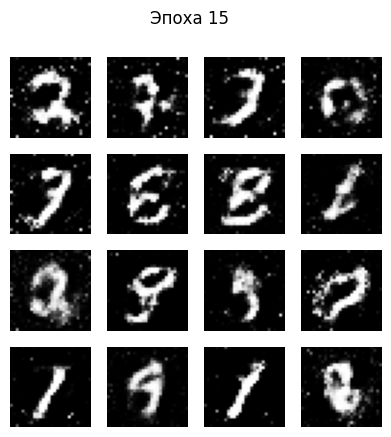

Эпоха 16/30  d_loss=0.975  g_loss=1.333
Эпоха 17/30  d_loss=0.998  g_loss=1.283
Эпоха 18/30  d_loss=1.004  g_loss=1.273
Эпоха 19/30  d_loss=1.013  g_loss=1.276
Эпоха 20/30  d_loss=1.009  g_loss=1.273


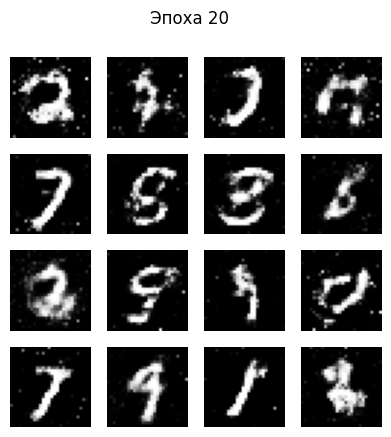

Эпоха 21/30  d_loss=1.010  g_loss=1.262
Эпоха 22/30  d_loss=1.013  g_loss=1.265
Эпоха 23/30  d_loss=1.013  g_loss=1.274
Эпоха 24/30  d_loss=1.010  g_loss=1.268
Эпоха 25/30  d_loss=1.013  g_loss=1.276


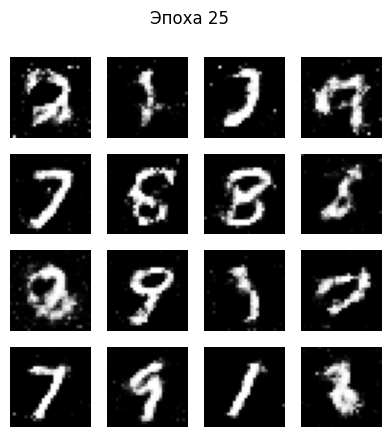

Эпоха 26/30  d_loss=1.012  g_loss=1.274
Эпоха 27/30  d_loss=1.008  g_loss=1.273
Эпоха 28/30  d_loss=1.004  g_loss=1.282
Эпоха 29/30  d_loss=1.002  g_loss=1.292
Эпоха 30/30  d_loss=1.002  g_loss=1.293


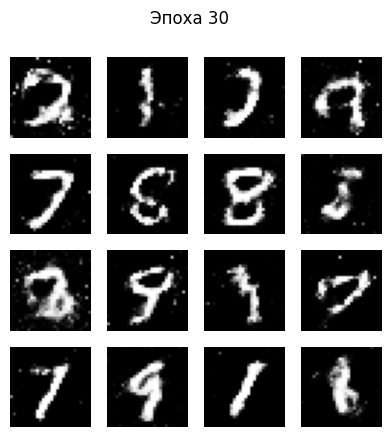

In [6]:
EPOCHS = 30
fixed_z = tf.random.normal((16, latent_dim))  # фиксированный шум для сравнения эпох

d_losses, g_losses = [], []

for epoch in range(1, EPOCHS + 1):
    d_sum, g_sum, n = 0.0, 0.0, 0
    for real in dataset:
        d_l, g_l = train_step(real)
        d_sum += float(d_l); g_sum += float(g_l); n += 1
    d_losses.append(d_sum / n); g_losses.append(g_sum / n)
    print(f"Эпоха {epoch}/{EPOCHS}  d_loss={d_losses[-1]:.3f}  g_loss={g_losses[-1]:.3f}")

    # каждые 5 эпох (и после первой) показываем 16 цифр из фиксированного шума
    if epoch == 1 or epoch % 5 == 0:
        show_grid(generator(fixed_z).numpy(), 4, 4, title=f"Эпоха {epoch}")

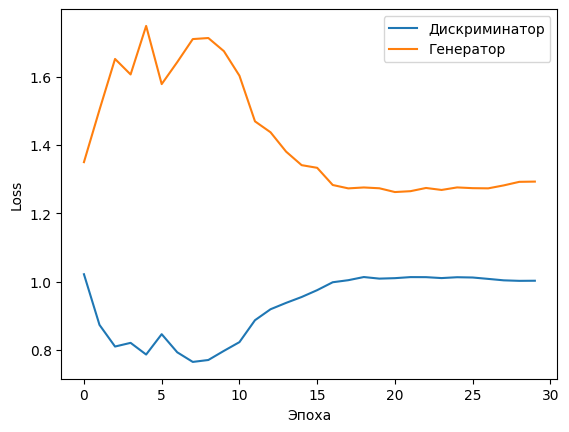

In [7]:
# Бонус: графики потерь
plt.plot(d_losses, label="Дискриминатор")
plt.plot(g_losses, label="Генератор")
plt.xlabel("Эпоха"); plt.ylabel("Loss"); plt.legend(); plt.show()

## Шаг 4 — Генерация

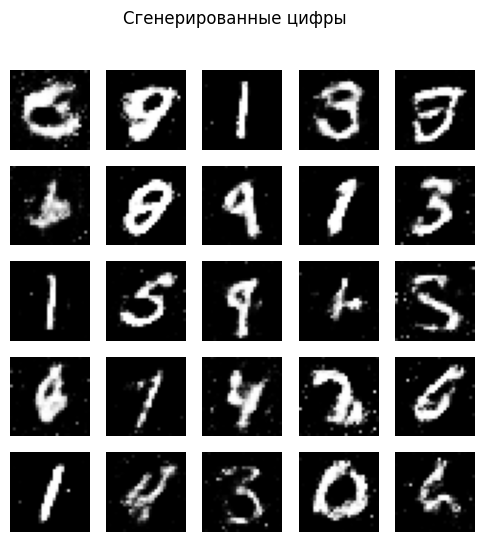

In [8]:
z = tf.random.normal((25, latent_dim))
show_grid(generator(z).numpy(), 5, 5, title="Сгенерированные цифры")

## Вывод

Первые узнаваемые цифры стали появляться примерно на 15-й эпохе, дальше качество продолжало улучшаться. К 30-й эпохе большинство образцов в финальной сетке читаются как цифры (различимы 0, 1, 3, 4, 5, 6, 8, 9), но часть изображений остаётся нечёткой: встречаются шумные пятна и искажённые штрихи, не похожие на цифры. Разнообразие достаточно высокое: сгенерированы разные классы, а образцы одного класса отличаются наклоном и толщиной линий, поэтому признаков mode collapse не видно. К концу обучения потери стабилизировались (d_loss ≈ 1.0, g_loss ≈ 1.29), то есть дискриминатор и генератор остались в равновесии, и ни одна из сетей не переиграла другую.